# 03 — Tái lập backtest, benchmark và báo cáo lịch sử

**Đầu vào:** canonical targets, ledger, holdings, turnover, NAV, metrics, benchmark, input/config/code/seal đã pin.

**Đầu ra:** đối chiếu năm strategy ở hai đoạn, biểu đồ NAV/drawdown, báo cáo kỹ thuật và `03_verification.json`.

Gọi `engine.run`, `PriceBook`, benchmark và hàm metrics của runner chính thức. Không gọi CLI tạo run M3-A mới, không sửa artifact đã seal. Canonical targets là đầu vào schedule; Q6 gọi lại `Strategies.target_for` để giữ đúng semantics. Notebook 02 kiểm chứng toàn bộ targets từ đầu vào.

In [1]:
from pathlib import Path
import sys
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "M3/sources.json").is_file())
sys.path.insert(0, str(root / "M3"))
from m3c import Context, table, NAMES
ctx = Context()
print("Code nguồn:", ctx.identity["source_commit"])
print("Code thực thi:", ctx.identity["execution_commit"])
print("Config và nguồn canonical: PASS")
print("Evidence:", ctx.output)

Code nguồn: c9c1f5f0c88f2dbb3ebbb50effa47003b24b66cf
Code thực thi: c9c1f5f0c88f2dbb3ebbb50effa47003b24b66cf
Config và nguồn canonical: PASS
Evidence: C:\Users\HP\Downloads\Phân cụm động lượng TTCK\M3\reproduction\20261104T150049600949Z


## 1. Tái lập engine và đối chiếu canonical outputs

Kiểm tra từng ledger field, holdings, NAV, turnover, metrics và VNINDEX. Kiểm tra CASH/tổng tỷ trọng, failed executed=0, SCALED=intended×scale, turnover hai chiều/(2×NAV), strict boundaries và count Q17. Dev/Holdout đều bắt đầu bằng vốn 1 riêng biệt và không tính Sharpe.

In [2]:
summary, details, curves = ctx.backtest()
table(summary)
print("BENCHMARK_AND_ACCOUNTING_PASS")

segment,strategy,NAV_rows,ledger_rows,holdings_rows,final_NAV,result
development,Combined,60,1228,802,2.1615234,PASS
development,Market-only,60,2449,1580,2.2881337,PASS
development,Financial-only,60,4491,3966,1.4074266,PASS
development,Equal-weight,60,28048,25598,2.5903046,PASS
development,Momentum-only,60,10210,7675,2.6973347,PASS
holdout,Combined,24,411,278,1.3894884,PASS
holdout,Market-only,24,1265,810,1.2242984,PASS
holdout,Financial-only,24,1980,1672,1.2836782,PASS
holdout,Equal-weight,24,18703,17758,1.2952863,PASS
holdout,Momentum-only,24,6779,5313,1.4137386,PASS


BENCHMARK_AND_ACCOUNTING_PASS


## 2. Bảng kết quả theo segment

Các tỷ suất hiển thị ở dạng tỷ lệ 0–1, ví dụ total_return=0,2 là 20%. Bảng báo cáo kỹ thuật sẽ định dạng %. Drawdown chỉ đo tại các ngày NAV được lưu. Số kỳ dưới N_min luôn được công bố cạnh kết quả.

In [3]:
for segment in ctx.runs:
    print(segment)
    table(ctx.metrics_table(segment), ["strategy", "total_return", "cagr", "volatility_annual", "max_drawdown", "avg_turnover", "avg_cash_after_trading", "too_small"])
    table(ctx.metrics_table(segment), ["strategy", "failed_buys", "failed_sells", "scaled_buys", "price_stale", "limit_data_missing"])

development


strategy,total_return,cagr,volatility_annual,max_drawdown,avg_turnover,avg_cash_after_trading,too_small
Combined,1.1615234,0.16973307,0.27393469,-0.44603841,0.4761748,0.22398996,13
Market-only,1.2881337,0.18335449,0.29509674,-0.47879257,0.53990276,0.062241724,0
Financial-only,0.40742665,0.071983972,0.17088917,-0.27202146,0.17690074,0.010227256,0
Equal-weight,1.5903046,0.21358823,0.24448098,-0.37011078,0.11893818,0.0048097922,0
Momentum-only,1.6973347,0.22362337,0.25514508,-0.33706917,0.31542485,0.014745574,0
VNINDEX,0.24349874,0.045321545,0.23560235,-0.33021199,,,


strategy,failed_buys,failed_sells,scaled_buys,price_stale,limit_data_missing
Combined,47,33,263,2,0
Market-only,96,62,537,3,0
Financial-only,267,280,1301,9,0
Equal-weight,1836,2027,11115,111,0
Momentum-only,661,739,2735,26,0
VNINDEX,0,0,0,,


holdout


strategy,total_return,cagr,volatility_annual,max_drawdown,avg_turnover,avg_cash_after_trading,too_small
Combined,0.38948837,0.18722491,0.28593445,-0.26272105,0.54526475,0.089225085,1
Market-only,0.22429845,0.11135867,0.23746687,-0.18905219,0.58518559,0.03749128,0
Financial-only,0.28367824,0.1391629,0.072995681,-0.039514974,0.24367205,0.025425229,0
Equal-weight,0.29528633,0.1445259,0.13336252,-0.073950691,0.084090843,0.0047364094,0
Momentum-only,0.41373857,0.1979907,0.15597717,-0.089162024,0.27503951,0.0081719508,0
VNINDEX,0.52127841,0.24470206,0.1608193,-0.058664116,,,


strategy,failed_buys,failed_sells,scaled_buys,price_stale,limit_data_missing
Combined,17,23,93,3,0
Market-only,40,25,254,5,0
Financial-only,123,96,614,1,0
Equal-weight,1073,1169,9019,29,0
Momentum-only,409,464,2430,6,0
VNINDEX,0,0,0,,


## 3. Ví dụ giao dịch, danh mục và stale

Các giá trị executed/intended là vốn chuẩn hóa, không phải số cổ phiếu hoặc triệu đồng. weight là tỷ trọng. Các ví dụ được lấy trực tiếp từ kết quả engine đã đối chiếu.

In [4]:
for segment in ctx.runs:
    res = details[segment, "combined"]
    examples = []
    for status in ["BUY_FAILED", "SELL_FAILED", "SCALED"]:
        examples += [r for r in res["ledger"] if r["status"] == status][:2]
    print(segment, "ví dụ ledger")
    table(examples)
    print("PRICE_STALE:", res["stale"])
    first_date = res["nav"][0][0]
    table([r for r in res["holdings"] if r["date"] == first_date])

development ví dụ ledger


date,ticker,side,pre_weight,target_weight,intended,executed,scale,status,flag
2019-03-01,HVT,BUY,0,0.047619048,0.048700624,0,1,BUY_FAILED,
2019-11-01,VNX,BUY,0,0.25,0.27174368,0,1,BUY_FAILED,
2019-07-01,WCS,SELL,0.19123955,0,0.2144697,0,1,SELL_FAILED,
2019-12-02,D2D,SELL,0.23090783,0,0.25152902,0,1,SELL_FAILED,
2019-07-01,NDN,BUY,0,0.2,0.2242943,0.1528044,0.68126742,SCALED,
2019-07-01,TIP,BUY,0,0.2,0.2242943,0.1528044,0.68126742,SCALED,


PRICE_STALE: [('2021-08-02', 'TVD'), ('2021-08-02', 'VSA')]


date,ticker,weight
2019-02-01,AMV,0.052631579
2019-02-01,CAP,0.052631579
2019-02-01,CNG,0.052631579
2019-02-01,D2D,0.052631579
2019-02-01,DHA,0.052631579
2019-02-01,DSN,0.052631579
2019-02-01,FMC,0.052631579
2019-02-01,GDT,0.052631579
2019-02-01,GHC,0.052631579
2019-02-01,GIL,0.052631579


holdout ví dụ ledger


date,ticker,side,pre_weight,target_weight,intended,executed,scale,status,flag
2024-02-01,VFC,BUY,0,0.033333333,0.033333333,0,1,BUY_FAILED,
2024-02-01,VFG,BUY,0,0.033333333,0.033333333,0,1,BUY_FAILED,
2024-10-01,CID,SELL,0.11969524,0.076923077,0.03778911,0,1,SELL_FAILED,
2024-10-01,PTX,SELL,0.092349933,0,0.081590967,0,1,SELL_FAILED,
2024-10-01,ADP,BUY,0,0.076923077,0.067961374,0.050907077,0.74905897,SCALED,
2024-10-01,DTP,BUY,0,0.076923077,0.067961374,0.050907077,0.74905897,SCALED,


PRICE_STALE: [('2024-10-01', 'PTX'), ('2024-11-01', 'PTX'), ('2025-12-01', 'VVS')]


date,ticker,weight
2024-02-01,AVC,0.033333333
2024-02-01,BMC,0.033333333
2024-02-01,BMP,0.033333333
2024-02-01,CSV,0.033333333
2024-02-01,DCM,0.033333333
2024-02-01,DGC,0.033333333
2024-02-01,DGW,0.033333333
2024-02-01,DHA,0.033333333
2024-02-01,DP3,0.033333333
2024-02-01,DRC,0.033333333


## 4. Đường NAV và drawdown

Mỗi segment có một hình chính chỉ gồm **Combined và VNINDEX**. Bốn strategy đối chứng được tách thành các hàng riêng; mỗi ô chỉ có hai đường, Combined luôn màu xanh liền, đối chứng màu cam đứt. Các ô cùng cột dùng chung thang đo.

Hai segment có vốn đầu=1 riêng biệt. Strategy dùng giá điều chỉnh; VNINDEX là price index. Khác biệt này ảnh hưởng cả lợi suất và drawdown. Baseline chưa tính chi phí/trượt giá.


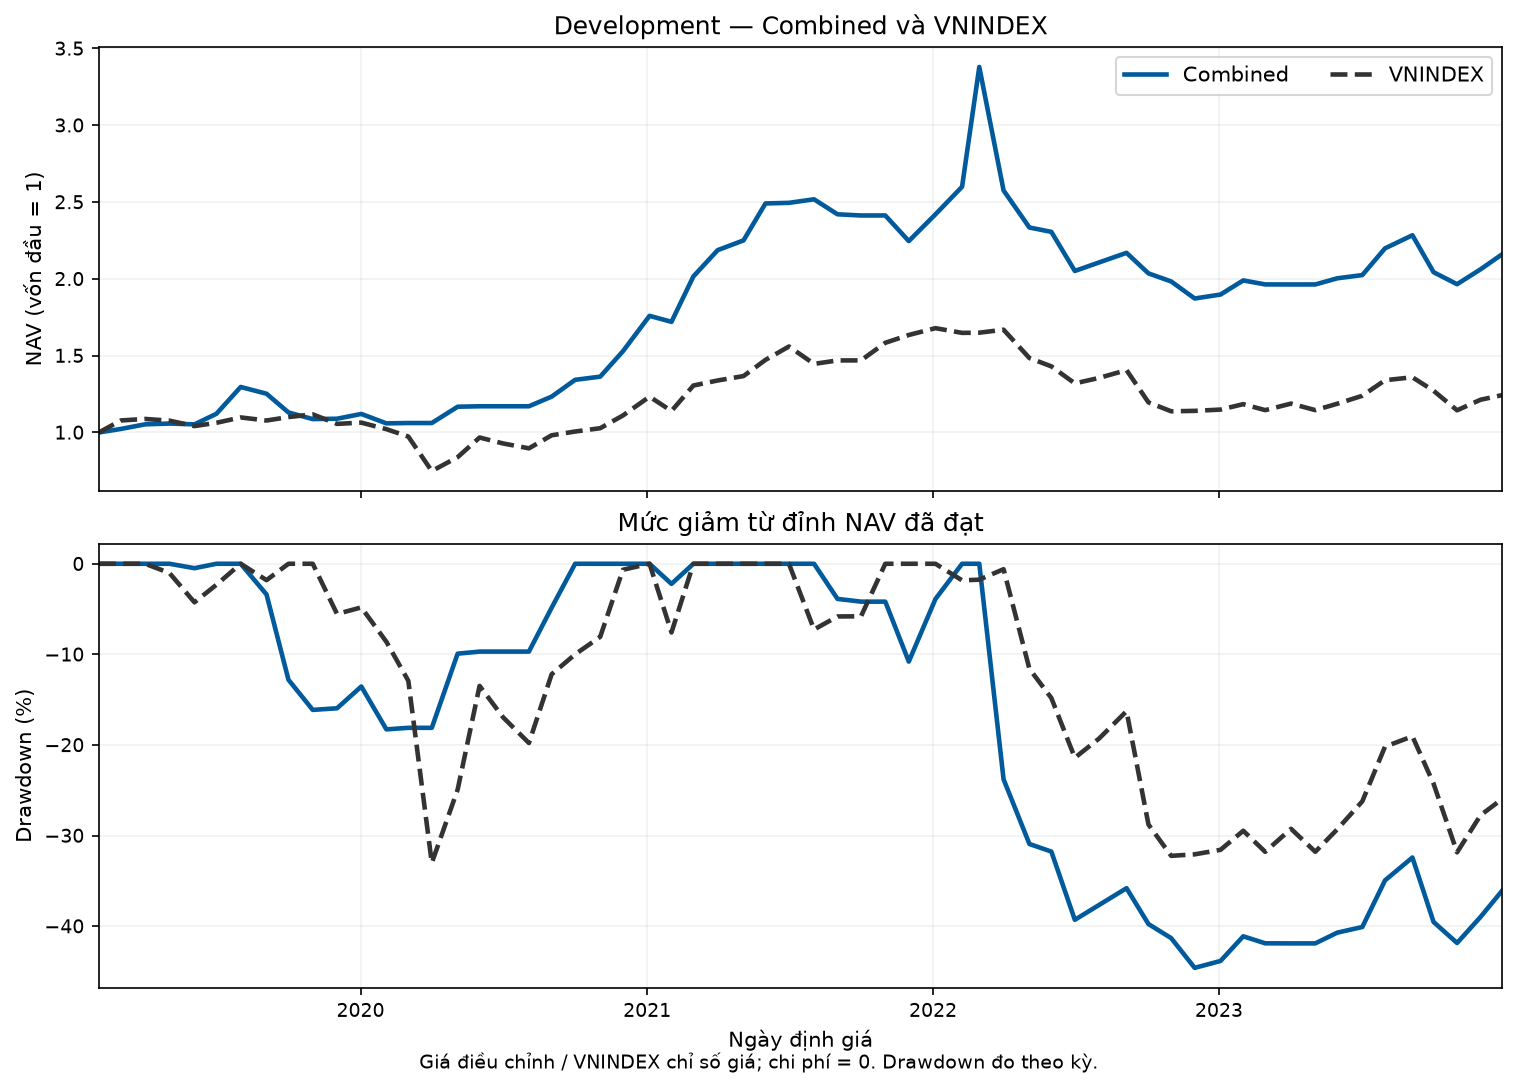

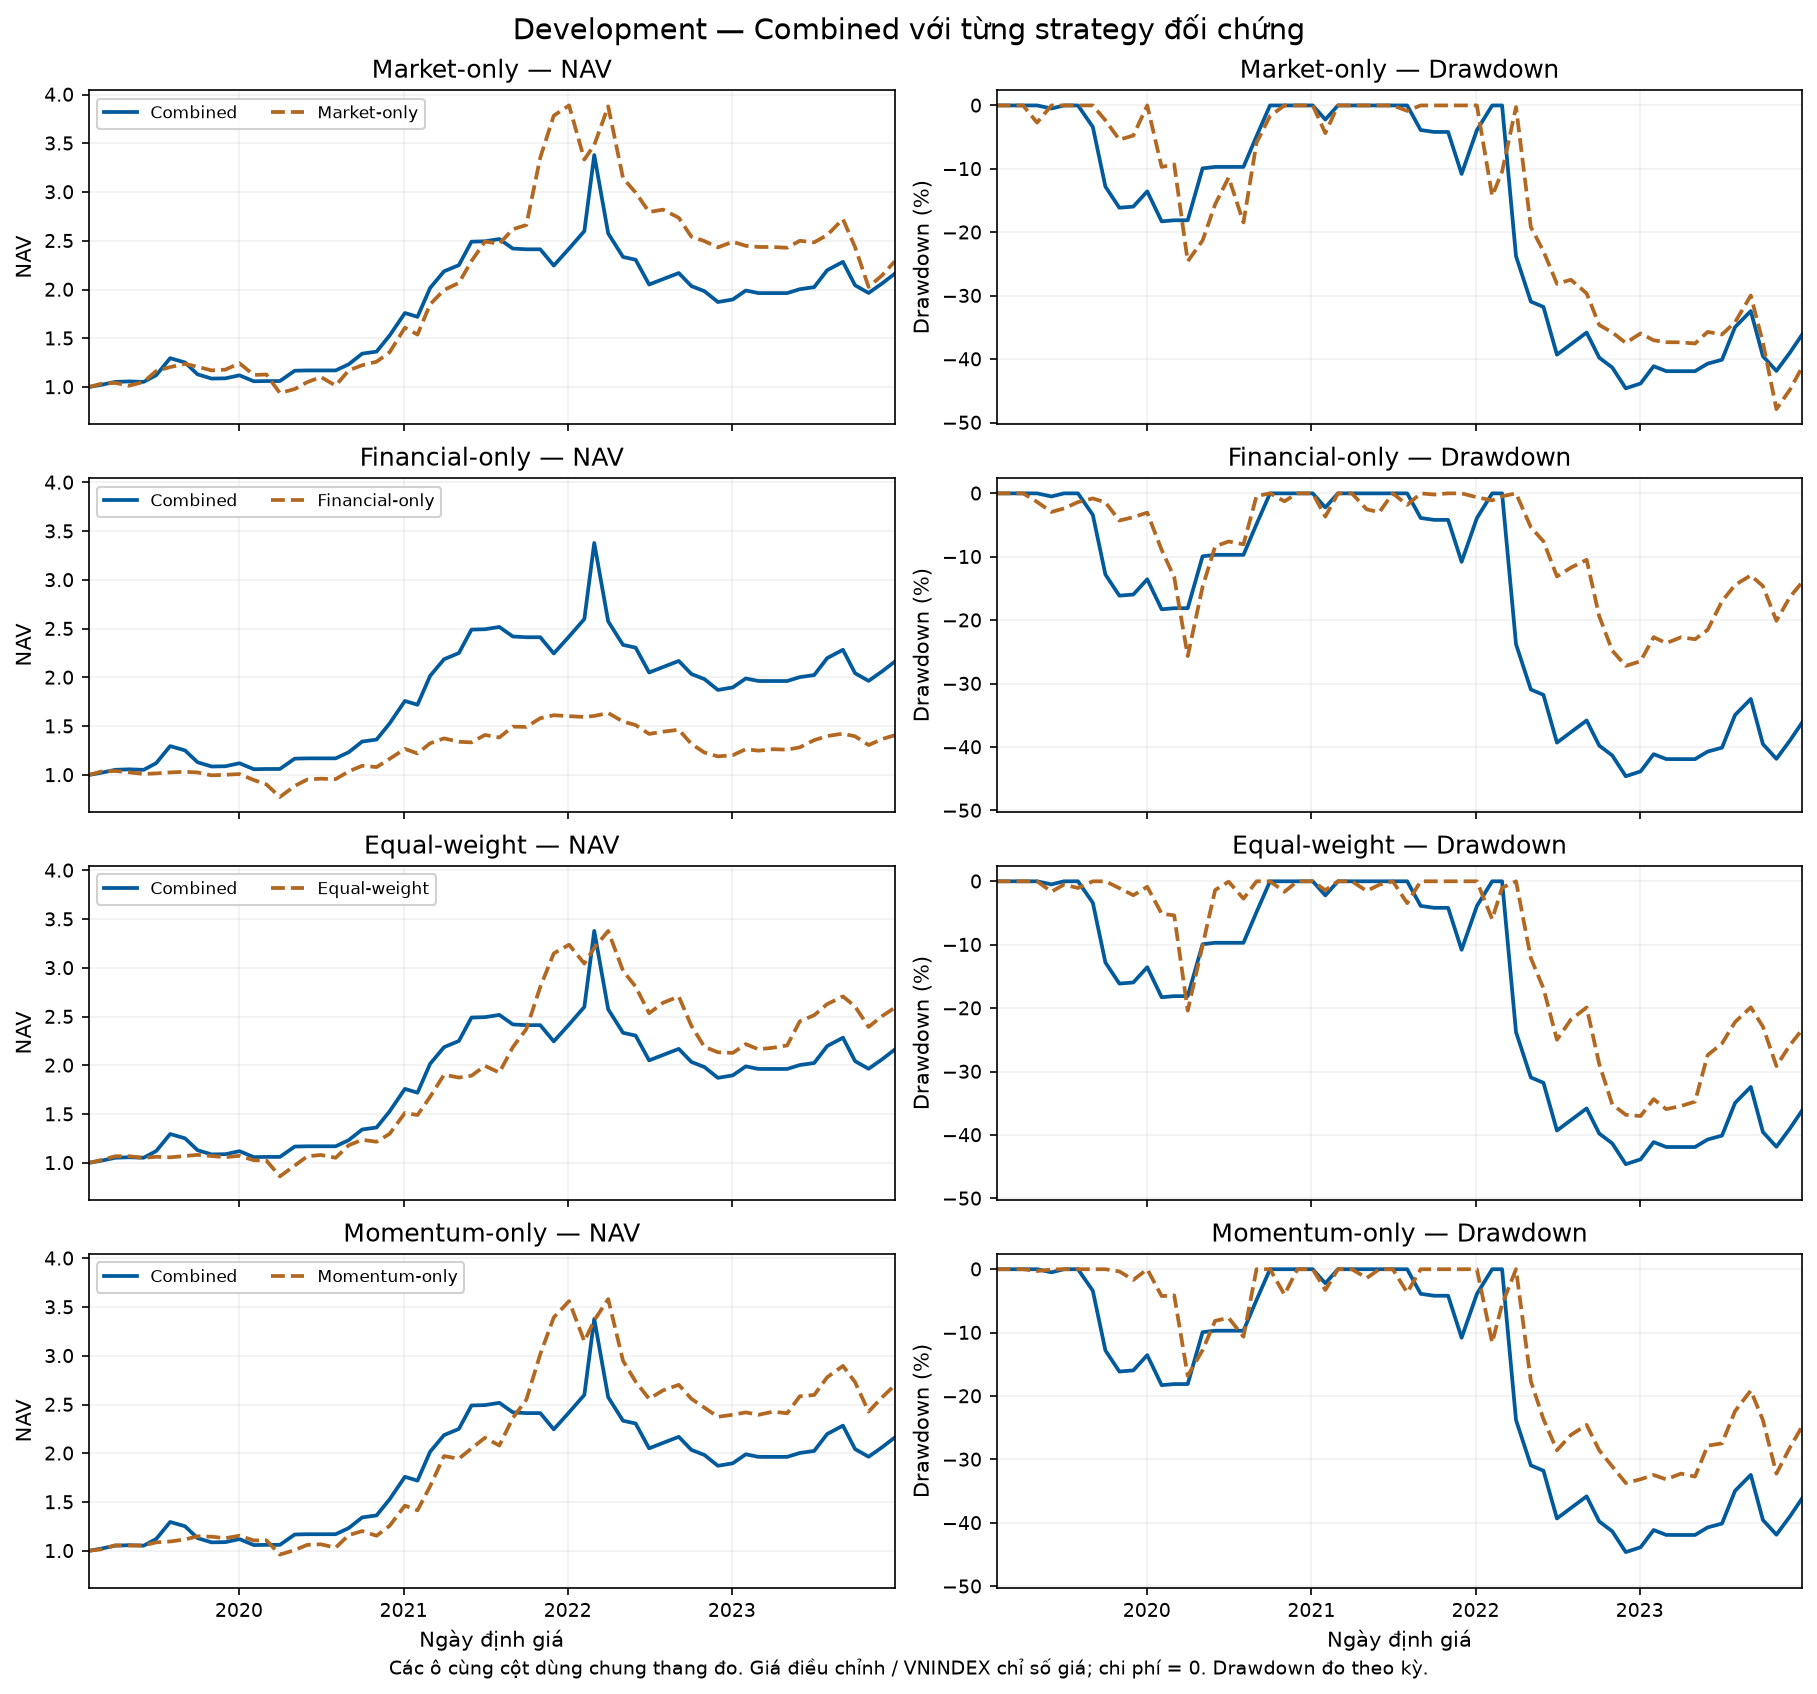

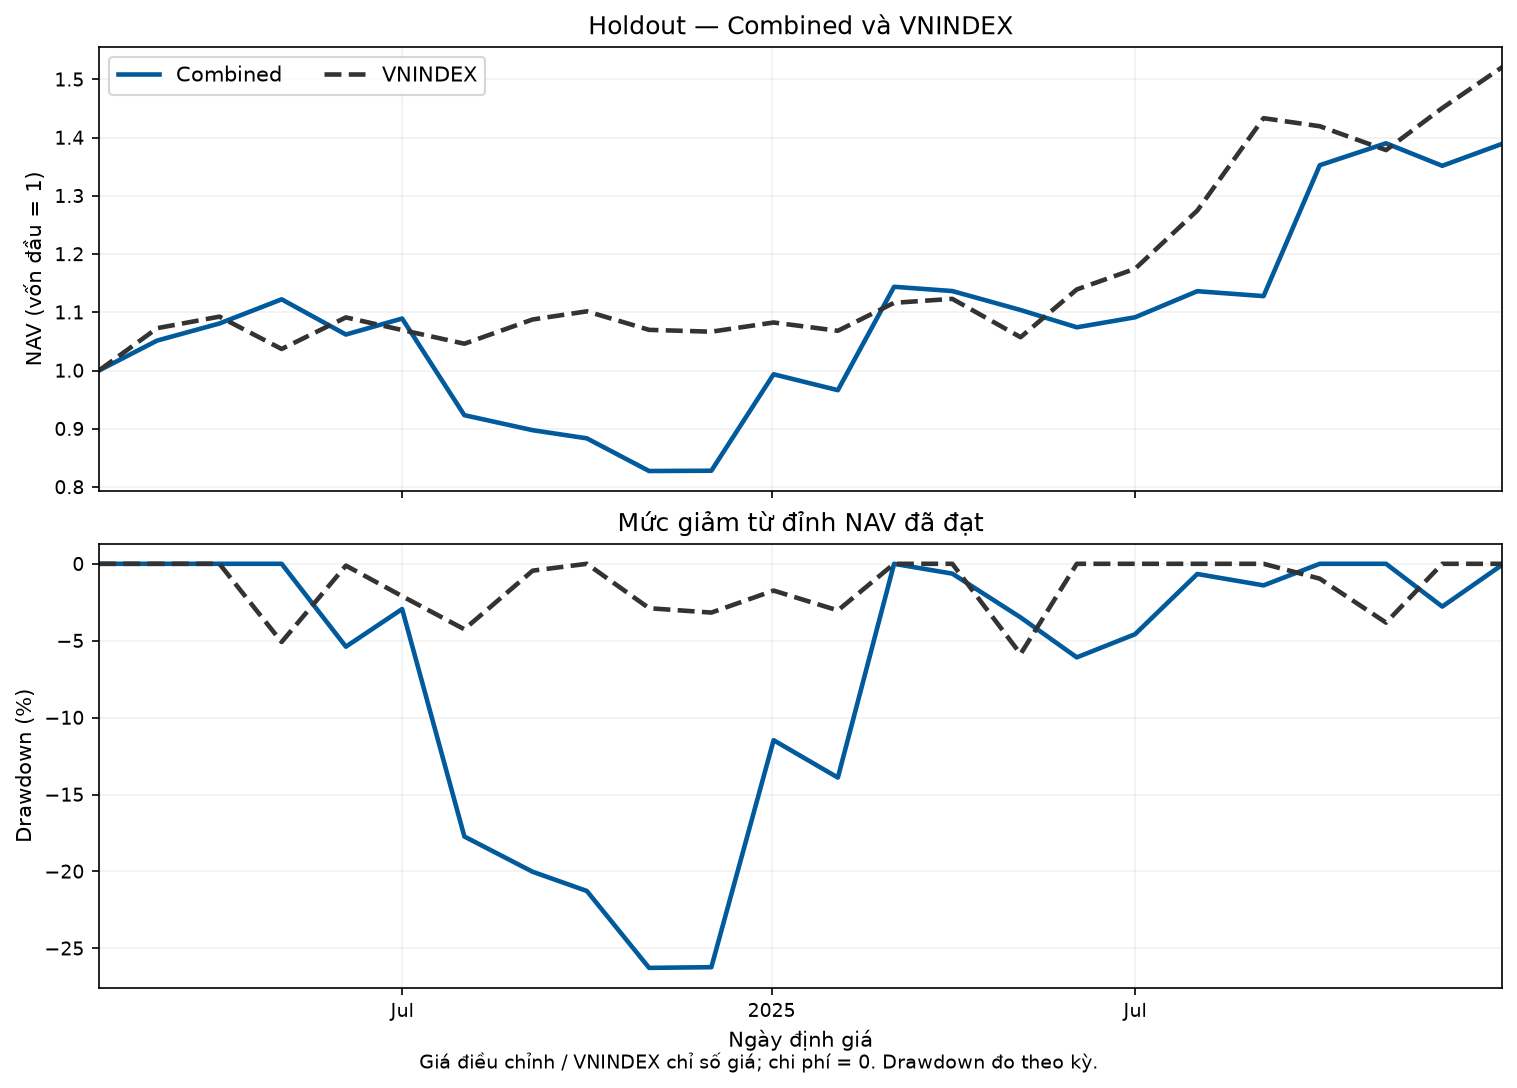

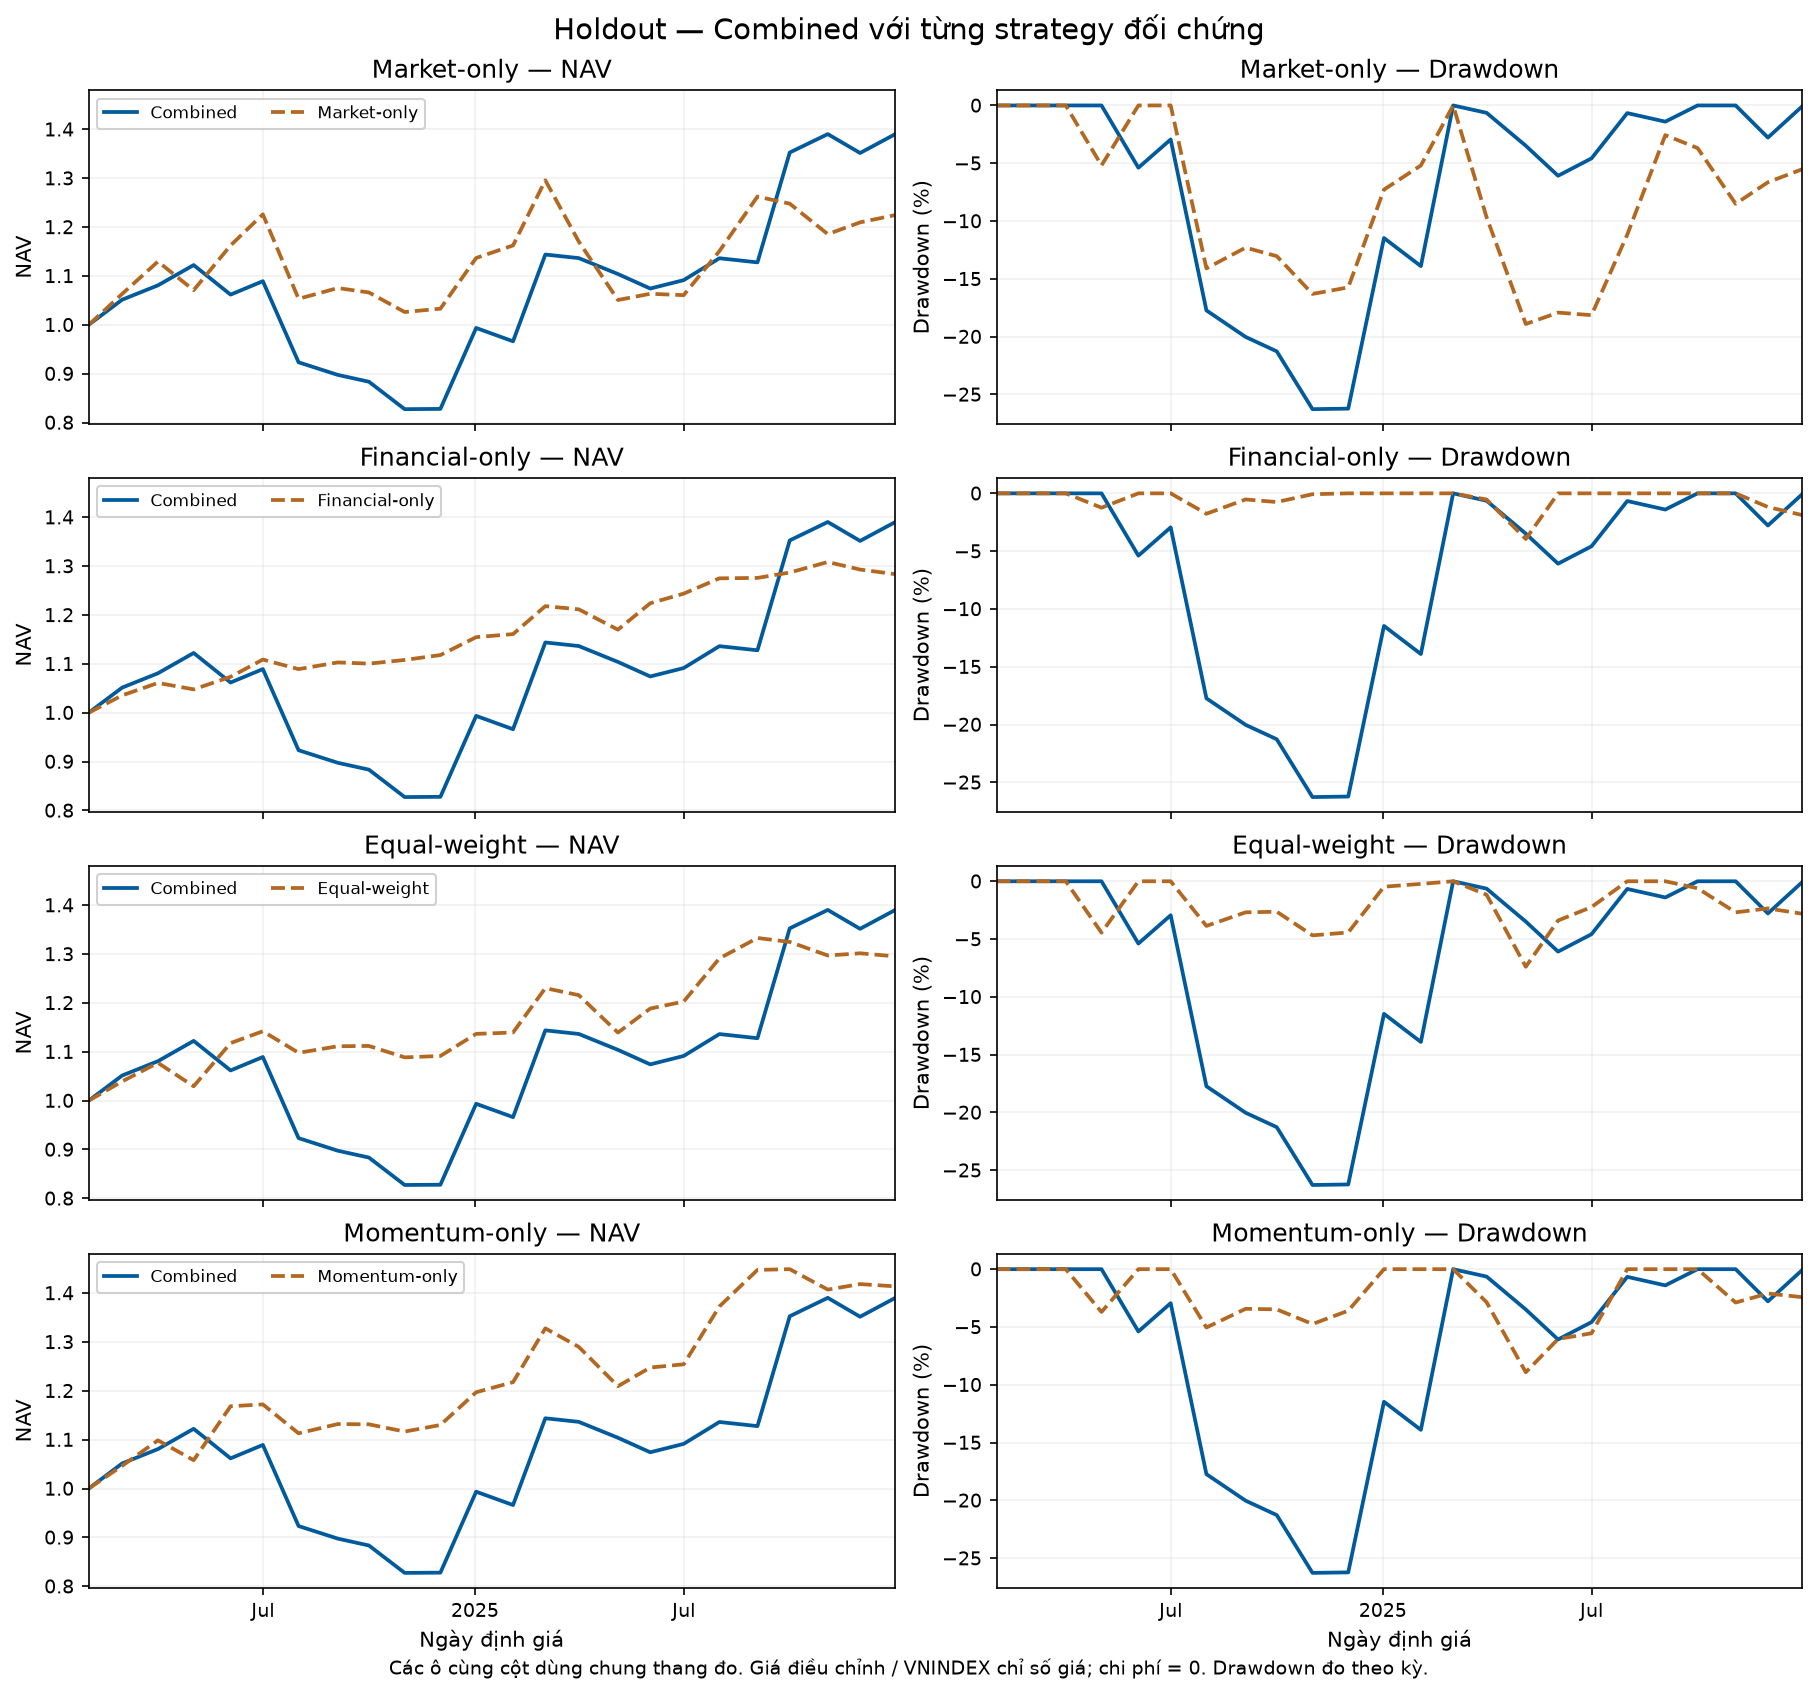

In [5]:
from IPython.display import Image, display
figures = ctx.plot(curves)
for file in figures:
    display(Image(filename=str(file)))

### Nhận xét biểu đồ Development

- Combined tăng mạnh đến đầu năm 2022, sau đó giảm sâu và chưa trở lại đỉnh cũ khi kết thúc Dev.
- NAV cuối **2,162**, lợi suất **116,15%**, nhưng drawdown **−44,60%** cho thấy danh mục đã mất lại nhiều thành quả trong quá trình nắm giữ.
- Momentum-only và Equal-weight có NAV cuối cao hơn, đồng thời giảm ít sâu hơn Combined; phương án kết hợp chưa cho thấy ưu thế ở đoạn này.


### Nhận xét biểu đồ Holdout

- Combined giảm dưới vốn ban đầu vào cuối năm 2024, rồi phục hồi trong năm 2025, kết thúc với NAV **1,389** và lợi suất **38,95%**.
- Lợi suất cao hơn ba strategy đối chứng, nhưng vẫn thấp hơn Momentum-only và VNINDEX.
- Drawdown **−26,27%** sâu nhất nhóm đối sánh: kết quả cuối kỳ khá hơn nhưng đường đi vẫn nhiều rủi ro.


### Lưu ý khi đọc

Drawdown là mức giảm từ đỉnh NAV đã đạt, chỉ đo tại các ngày định giá theo kỳ. Strategy và VNINDEX khác cơ sở giá; backtest chưa tính phí và trượt giá.


## 5. Báo cáo kỹ thuật và kết luận

Báo cáo sinh từ đúng metrics đã kiểm tra, gồm phương pháp, phân tích từng đối chứng, điều kiện vận hành và giới hạn. Final chưa có dữ liệu đủ nên không tạo Sharpe hoặc kết quả Final. M3-C tổng thể còn PARTIAL.

In [6]:
report = ctx.write_report()
print("Báo cáo:", report)
print(ctx.finish())
print("NOTEBOOK_03_PASS; FINAL_NOT_READY")

Báo cáo: C:\Users\HP\Downloads\Phân cụm động lượng TTCK\M3\reports\BAO_CAO_KY_THUAT_M3.md


PASS — nguồn canonical giữ nguyên; không có Final performance.
NOTEBOOK_03_PASS; FINAL_NOT_READY
